<a href="https://colab.research.google.com/github/katepashchenko/python_test/blob/main/%D0%9A%D0%BE%D0%BF%D1%96%D1%8F_%D0%B7%D0%B0%D0%BF%D0%B8%D1%81%D0%BD%D0%B8%D0%BA%D0%B0_%22HW_11_3_%D0%A1%D1%82%D0%B0%D1%82%D0%B8%D1%81%D1%82%D0%B8%D1%87%D0%BD%D1%96_%D0%B2%D1%96%D0%B7%D1%83%D0%B0%D0%BB%D1%96%D0%B7%D0%B0%D1%86%D1%96%D1%97_%D0%B7_Seaborn_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашнє завдання: Статистичні візуалізації з Seaborn

## Опис завдання
У цьому домашньому завданні ви будете використовувати бібліотеку Seaborn для створення красивих статистичних візуалізацій. Seaborn має кращий стандартний стиль та спеціалізується на статистичних графіках.

**Опис колонок:**
- `datetime` - дата та час
- `season` - квартал (1-Q1, 2-Q2, 3-Q3, 4-Q4)
- `holiday` - чи є день святковим (0=ні, 1=так)
- `workingday` - чи є день робочим (0=ні, 1=так)
- `weather` - погодні умови (1=ясно, 2=туман, 3=легкий дощ, 4=сильний дощ)
- `temp` - температура в градусах Цельсія
- `atemp` - як відчувається температура
- `humidity` - вологість (%)
- `windspeed` - швидкість вітру
- `casual` - кількість випадкових користувачів
- `registered` - кількість зареєстрованих користувачів
- `count` - загальна кількість орендованих велосипедів

## Підготовка даних

---
🌱 Коментар щодо сезонності

Колонка season у датасеті представляє саме квартали року, а не метеорологічні сезони. Тому всі аналізи сезонності ви можете будувати на основі кварталів.

Водночас дані були зібрані в Індії, де поділ на сезони інший, ніж у Європі чи США. Якщо ви хочете дослідити сезонність відповідно до індійської системи сезонів, можна створити окрему колонку.

Справжні сезони в Індії:

| Сезон        | Місяці                     |
| ------------ | -------------------------- |
| Winter       | December–February (12,1,2) |
| Summer       | March–May (3,4,5)          |
| Monsoon      | June–September (6,7,8,9)   |
| Post-monsoon | October–November (10,11)   |


Тоді потрібно зробити нову колонку weather_season_india, мапнувши місяці так:

12, 1, 2 → 1 (Winter)

3, 4, 5 → 2 (Summer)

6–9 → 3 (Monsoon)

10–11 → 4 (Post-Monsoon)

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Завантаження даних
from google.colab import drive
drive.mount('/content/drive')
df = pd.read_csv ('drive/MyDrive/yulu_bike_sharing_dataset.csv')
df['datetime'] = pd.to_datetime(df['datetime'])
df.set_index('datetime', inplace=True)

# Встановлюємо стиль seaborn
sns.set_theme(style="whitegrid")

# Додамо додаткові колонки для аналізу
df['date'] = df.index.date
df['day'] = df.index.day
df['week'] = df.index.isocalendar().week
df['weekday_num'] = df.index.weekday
df['weekday'] = df.index.day_name()
df['year'] = df.index.year
df['month'] = df.index.month
df['hour'] = df.index.hour

Mounted at /content/drive



---

## Завдання 1: Лінійний графік з довірчими інтервалами

**Завдання:**
Побудуйте лінійний графік середньої кількості оренд помісячно з довірчими інтервалами (confidence intervals) рівними 1 стандартному відхиленню.

**УВАГА!** В лекції ми будували подібний графік, але там були дані по номеру місяця, а тут треба зобразити дані в розрізі місяць_рік.

В якості підказки вам наведений код для створення колонки, яка містить `місяць_рік`. Як її використати - вже питання до вас :)

Очікуваний результат:
![](https://drive.google.com/uc?id=1uVKqfY1VlhVMaM3wu99uVGT1f7S0Vf8S)

**Питання для інтерпретації:**
- В які місяці найбільша невизначеність в даних?

In [2]:
df['month_year'] = df.index.to_period('M')
df['month_year']  = df.month_year.astype(str)

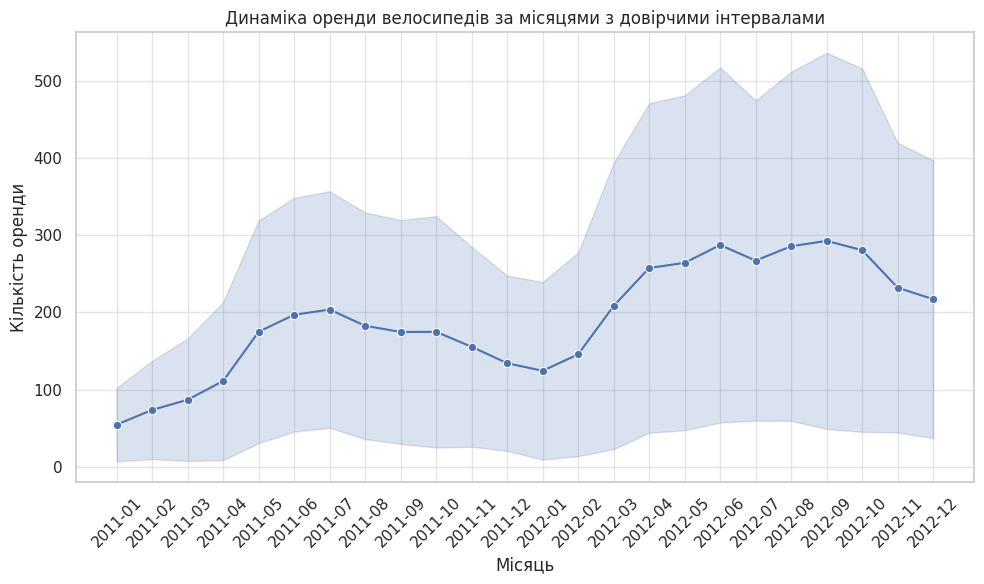

In [27]:

plt.figure(figsize=(10, 6))
sns.lineplot(df, x='month_year', y='count', errorbar='sd', marker='o', linestyle='-')
plt.title('Динаміка оренди велосипедів за місяцями з довірчими інтервалами')
plt.xlabel('Місяць')
plt.ylabel('Кількість оренди')
plt.xticks(rotation=45)
plt.grid(alpha=0.5)
plt.tight_layout();

Найбільша невизначеність в даних в місяці 2012-06, 2012-08, 09,10

## Завдання 2: Порівняння стилів - Pandas vs Seaborn гістограма

**Завдання:**
Побудуйте гістограму розподілу температури двома способами - з Pandas та Seaborn - та порівняйте візуальний вигляд. Задайте однакову кількість бінів в цих візуалізаціях, відмінну від стандартної. В візуалізації Seaborn додайте параметр при побудові `kde=True`.

**Функція Seaborn: `sns.histplot()`**

Можна побудувати окремо два графіки. Але для тих, хто хоче складніше - побудуйте ці 2 графіки на 1 фігурі.

**Дайте відповідь на питання:**
1. Яка візуальна різниця між Pandas та Seaborn гістограмами?
2. Що за лінія додаткова на графіку в Seaborn? Як вона називається і як ви б її описали своїми словами?

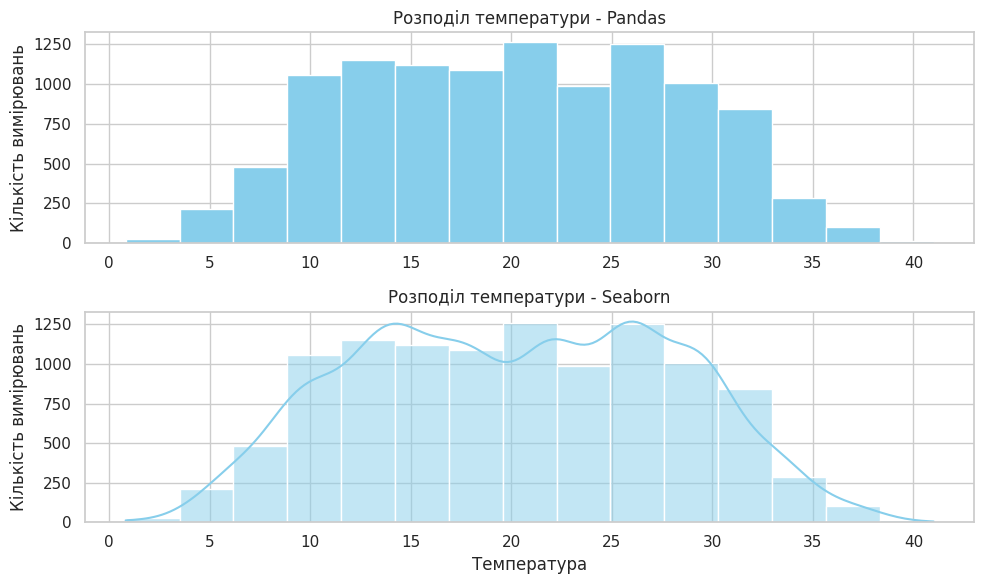

In [48]:
plt.figure(figsize=(10, 6))

plt.subplot(2, 1, 1)
df['temp'].plot(
    kind='hist',
    bins=15,
    color='skyblue',
    #xlabel='Температура',
    ylabel='Кількість вимірювань',
    title='Розподіл температури - Pandas',
    grid=True
);
plt.subplot(2, 1, 2)
sns.histplot(df['temp'], bins=15, color='skyblue', kde=True)
plt.title('Розподіл температури - Seaborn')
plt.xlabel('Температура')
plt.ylabel('Кількість вимірювань')

plt.tight_layout()
plt.show()

Обидві гістограми показують однаковий розподіл температури, оскільки використовуються ті самі дані та однакова кількість бінів. Візуально графік Seaborn виглядає більш інформативно завдяки параметру kde=True, який додає плавну криву та допомагає краще побачити форму розподілу даних. Також, колір skyblue має різні відтінки

## Завдання 3: Box Plot порівняння - Pandas vs Seaborn

**Завдання:**
Побудуйте box plot для кількості погодинних оренд велосипедів за погодними умовами з Pandas та Seaborn.

**Функція Seaborn: `sns.boxplot()`**

Можна побудувати окремо два графіки. Але для тих, хто хоче складніше - побудуйте ці 2 графіки на 1 фігурі.

Просунуте доповнення:
- підпишіть погодні умови їх інтерпретацією з опису даних в обох графіках

**Дайте відповідь на питання:**
- Яка візуальна різниця між Pandas та Seaborn бокс-плотами?

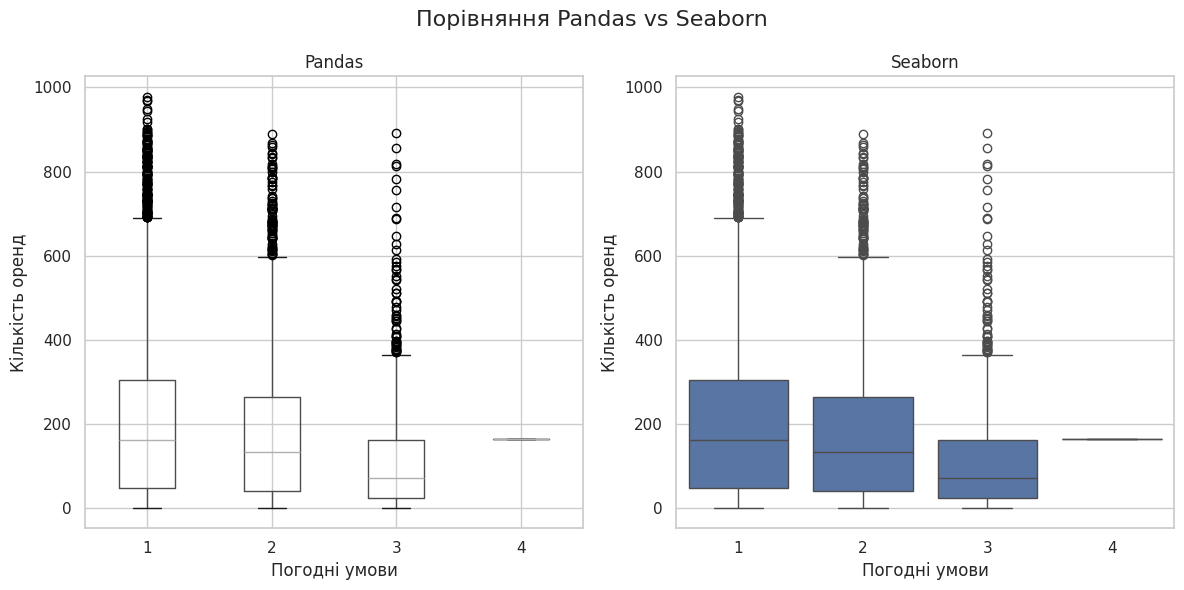

In [73]:

fig, ax = plt.subplots(1, 2, figsize=(12, 6))

df.boxplot(
    column='count',
    by='weather',
    ax=ax[0]
)

ax[0].set_xlabel('Погодні умови')
ax[0].set_ylabel('Кількість оренд')
ax[0].set_title('Pandas')
ax[0].get_figure().suptitle('')


sns.boxplot(
    data=df,
    x='weather',
    y='count',
    ax=ax[1]
)

ax[1].set_xlabel('Погодні умови')
ax[1].set_ylabel('Кількість оренд')
ax[1].set_title('Seaborn')


fig.suptitle('Порівняння Pandas vs Seaborn', fontsize=16)
fig.tight_layout()

plt.show()

Обидва графіки показують однаковий розподіл кількості оренд за погодними умовами. Pandas має більш простий стандартний вигляд, тоді як Seaborn - краща стилізація, кольорове оформлення та більш приємний вигляд. Pandas має grid клітинку, а Seaborn - горизонтільні лінії.

<!-- - -->
## Завдання 4: Heatmap кореляційної матриці

**Завдання:**
Створіть із Seaborn кореляційну матрицю з забарвленням heatmap (колір відповідає величині значення в клітинці) числових змінних в наших даних з анотаціями значень.

**Дайте відповіді на питання по графіку:**
1. Які змінні найсильніше корелюють з загальною кількістю оренди (count)?
2. Яка кореляція між temp та atemp? Чому?
3. Які змінні мають негативну кореляцію?


In [80]:
df.head()

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,date,day,week,weekday_num,weekday,year,month,hour,month_year
datetime,,,,,,,,,,,,,,,,,,,,
2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16,2011-01-01,1,52,5,Saturday,2011,1,0,2011-01
2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40,2011-01-01,1,52,5,Saturday,2011,1,1,2011-01
2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32,2011-01-01,1,52,5,Saturday,2011,1,2,2011-01
2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13,2011-01-01,1,52,5,Saturday,2011,1,3,2011-01
2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1,2011-01-01,1,52,5,Saturday,2011,1,4,2011-01


In [101]:
correlation = df[['humidity', 'count', 'temp', 'atemp', 'weather', 'casual', 'registered']].corr()

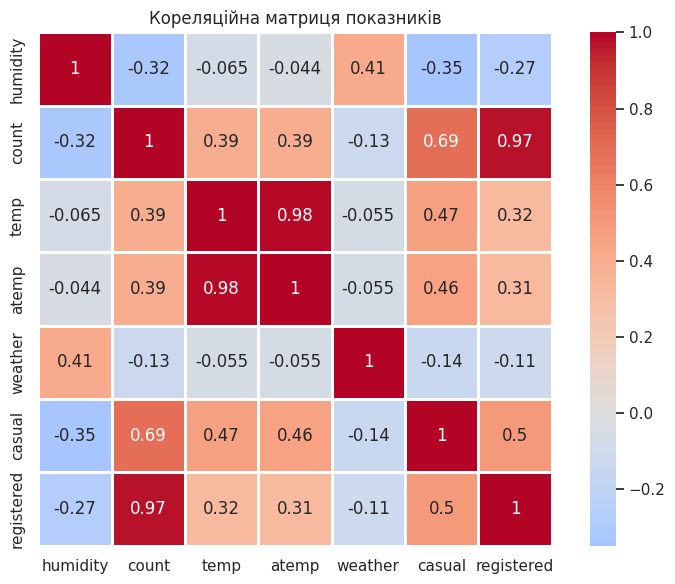

In [102]:
plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap='coolwarm', center=0,
            square=True, linewidths=1
            )
plt.title('Кореляційна матриця показників')
plt.tight_layout()
plt.show()

Які змінні найсильніше корелюють з загальною кількістю оренди (count)? - найсильніше корелюють зареєстровані та випадкові користувачі.

Яка кореляція між temp та atemp? Чому? Кореляція між temp і atemp = 0.98, так як описують майже одне й те саме — температуру. Коли фактична температура зростає, atemp теж зазвичай зростає.

Які змінні мають негативну кореляцію? Weather та humidity мають негативну кореляцію майже з усіма показниками.

## Завдання 5: Violin Plot для глибокого аналізу розподілів

**Завдання:**
Створіть violin plot для аналізу розподілу оренди за кварталами.

Дайте відповіді на питання:

**Питання для інтерпретації:**
1. Що показує "товщина" violin plot?
2. В якому кварталі найбільша варіабельність оренди?
3. Яка перевага violin plot над звичайним box plot?


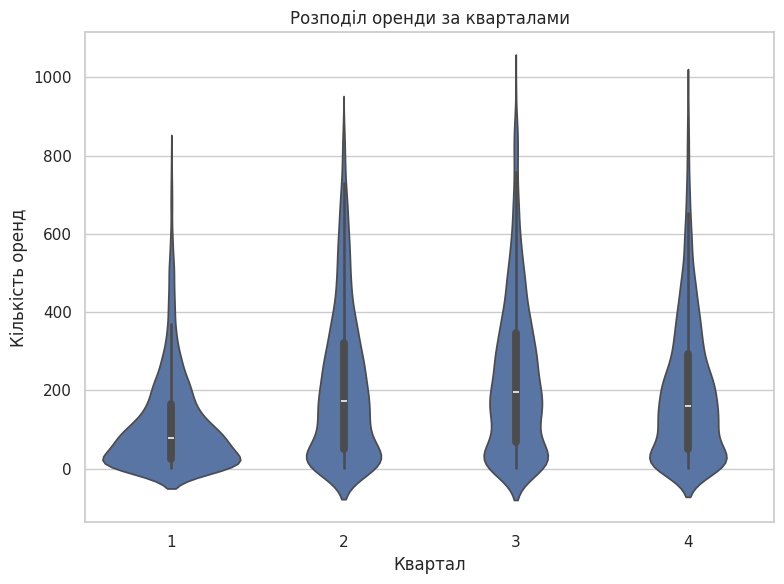

In [107]:
plt.figure(figsize=(8, 6))
sns.violinplot(data=df, x='season', y='count')
plt.title('Розподіл оренди за кварталами')
plt.xlabel('Квартал')
plt.ylabel('Кількість оренд')
plt.tight_layout()
plt.show()

1. Товщина violin показує щільність даних: ширше — більше спостережень.

2. Виходячи із загальної висоти violin та ширини розподілу, найімовірніше, 3-й квартал, оскільки в ньому оренда має найбільший розкид значень.

3. На відміну від box plot, violin plot додатково показує форму та щільність розподілу.

## Завдання 6 : Pairplot для мультиваріативного аналізу

**Завдання:**
Створіть pairplot для аналізу взаємозв'язків між ключовими змінними `'temp', 'humidity', 'windspeed', 'count'` . В якості візуальної розбивки за категоріями (параметр `hue`) додайте season (квартал).

Дайте відповіді на питання:

**Питання для інтерпретації:**
1. Між якими змінними спостерігається найсильніший лінійний зв'язок?
2. Яка характеристика найбільше відрізняється між кварталами?

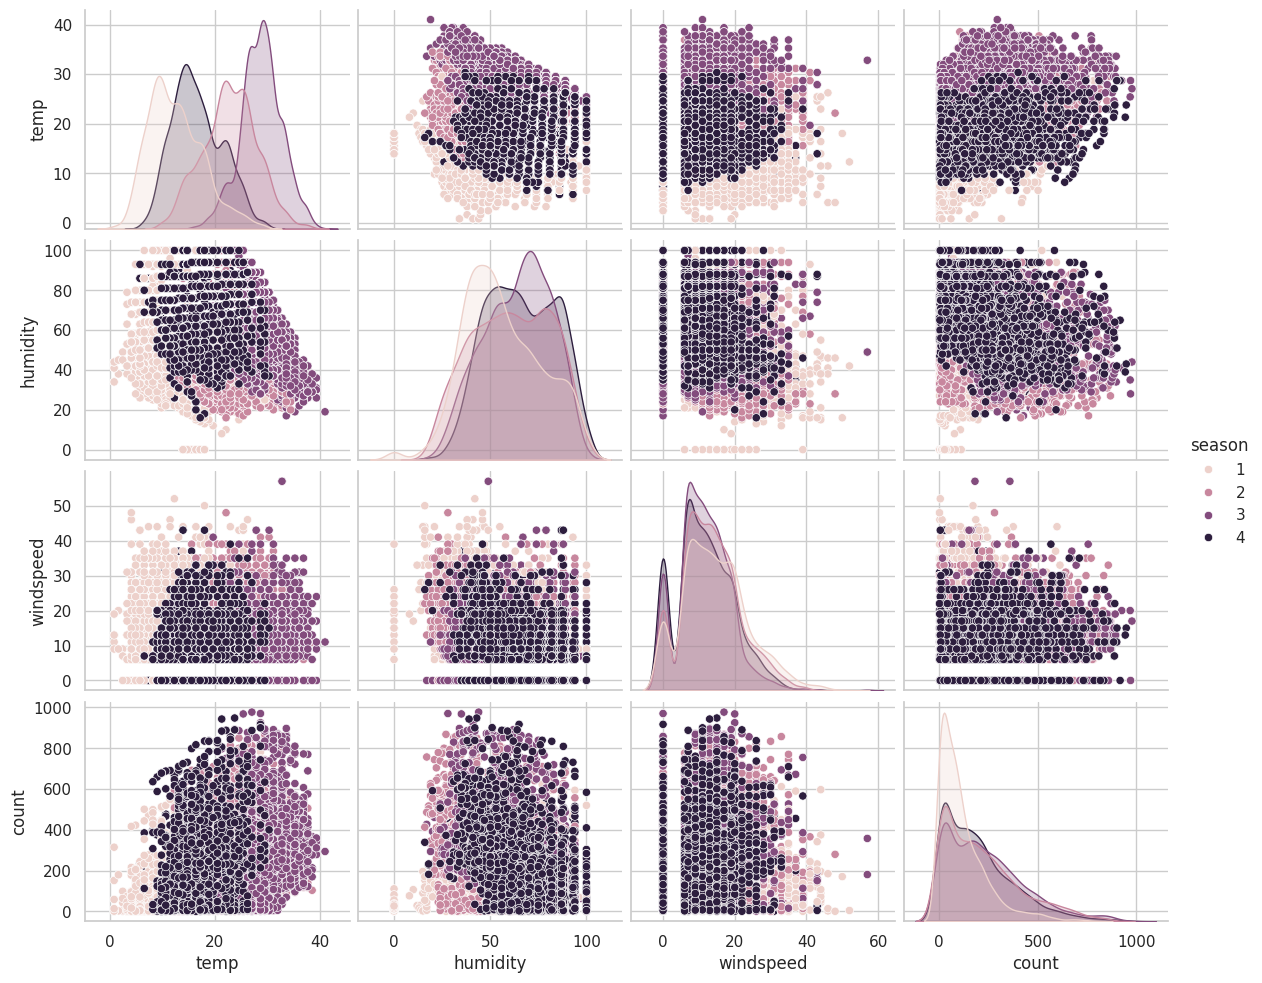

In [109]:
sns.pairplot(
    df[['temp', 'humidity', 'windspeed', 'count', 'season']],
    hue='season', height=2.5, aspect=1.2
)

plt.show()

1. Серед цих змінних найсильніший зв'язок спостерігається між temp та count — загалом він позитивний: зі зростанням температури кількість оренд збільшується.
2. Найбільше між кварталами відрізняється temp (температура), оскільки квартали відповідають різним періодам року, тому температура суттєво змінюється.

## Завдання 7: Joint Plot для детального аналізу двох змінних

**Завдання:**
Проаналізуйте залежність між температурою та орендою за допомогою joint plot. В якості візуальної розбивки за категоріями (параметр `hue`) додайте `workingday`.

Дайте відповіді на питання:

**Питання для інтерпретації:**
1. Що показують графіки по краях?
2. Чи є різниця у поведінці користувачів у робочий і неробочий день?

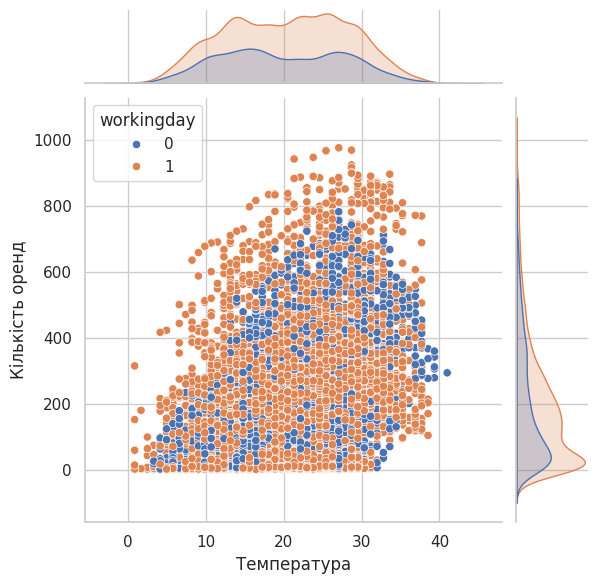

In [112]:
sns.jointplot(
    data=df,
    x='temp',
    y='count',
    hue='workingday'
)
plt.xlabel('Температура')
plt.ylabel('Кількість оренд')
plt.show()

1. Графіки по краях показують розподіл кожної окремої змінної, тобто, при яких значеннях температури та кількості оренд спостережень найбільше.:
верхній графік — розподіл temp (температури);
правий графік — розподіл count (кількості оренд).
2. У робочі дні оренда більш стабільна та пов'язана з регулярними поїздками, тоді як у неробочі дні попит може сильніше залежати від температури та інших погодних умов.
